In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('wine_data.csv', header=None, usecols=[0,1,2])
df.columns=["Class_label","Alcohol","Malic_Acid"]

In [3]:
df


,Class_label,Alcohol,Malic_Acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59
...,...,...,...
173,3,13.71,5.65
174,3,13.40,3.91
175,3,13.27,4.28
176,3,13.17,2.59


<Axes: xlabel='Alcohol', ylabel='Density'>

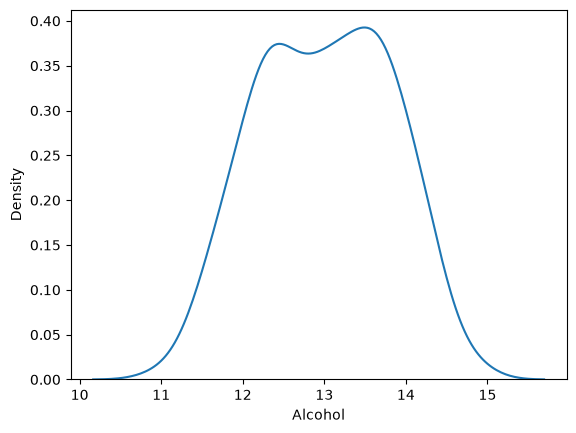

In [5]:
sns.kdeplot(df["Alcohol"])

<Axes: xlabel='Malic_Acid', ylabel='Density'>

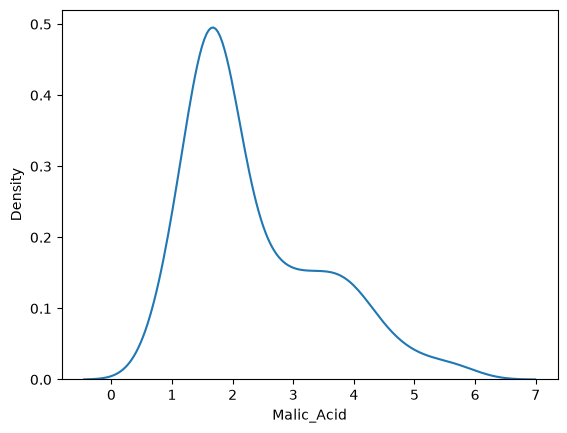

In [6]:
sns.kdeplot(df["Malic_Acid"])

<Axes: xlabel='Alcohol', ylabel='Malic_Acid'>

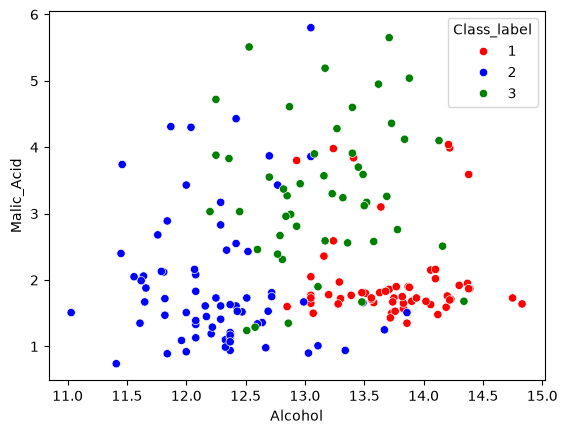

In [9]:
color_dict={1:'red',3:'green',2:'blue'}
sns.scatterplot(x=df['Alcohol'],y=df["Malic_Acid"],hue=df['Class_label'],palette=color_dict)

In [10]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.drop('Class_label',axis=1),
                                                df['Class_label'],
                                                test_size=0.3,
                                                random_state=0)

X_train.shape,X_test.shape

((124, 2), (54, 2))

In [11]:
from sklearn.preprocessing import MinMaxScaler

scaler= MinMaxScaler()

scaler.fit(X_train)

X_train_scaled=scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
X_train_scaled=pd.DataFrame(X_train_scaled,columns=X_train.columns)
X_train_scaled=pd.DataFrame(X_test_scaled,columns=X_test.columns)

In [13]:
np.round(X_train.describe(),1)

,Alcohol,Malic_Acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.9
25%,12.4,1.6
50%,13.0,1.9
75%,13.6,3.2
max,14.8,5.6


In [22]:
np.round(X_train_scaled.describe(),1)

,Alcohol,Malic_Acid
count,54.0,54.0
mean,0.5,0.3
std,0.2,0.2
min,0.1,-0.0
25%,0.4,0.1
50%,0.5,0.2
75%,0.7,0.4
max,1.0,1.0


ValueError: 'c' argument has 124 elements, which is inconsistent with 'x' and 'y' with size 54.

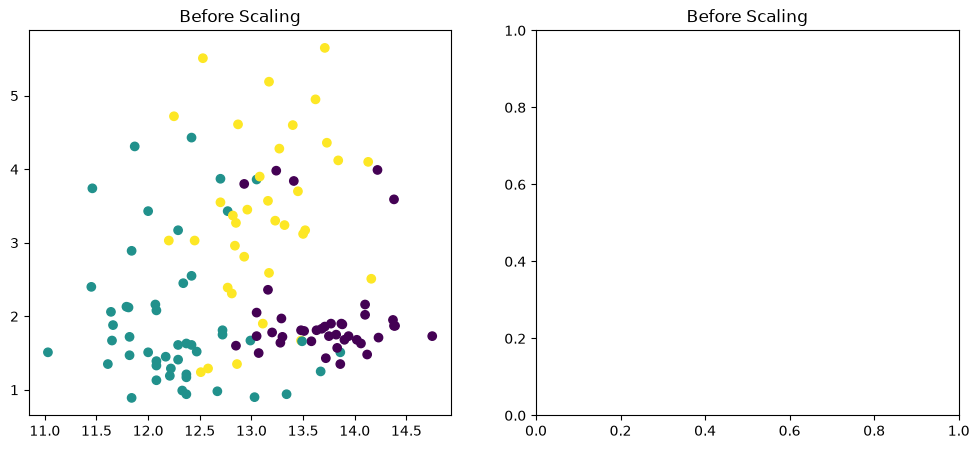

In [21]:
fig, (ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))

ax1.scatter(X_train['Alcohol'],X_train['Malic_Acid'],c=y_train)
ax1.set_title('Before Scaling')
# ax2.scatter(X_train_scaled['Age'],X_train_scaled['AnnualSalary'],color='Red')
# plt.show()fig, (ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))

# ax1.scatter(X_train['Age'],X_train['AnnualSalary'])
ax2.set_title('Before Scaling')
ax2.scatter(X_train_scaled['Alcohol'],X_train_scaled['Malic_Acid'],c=y_train)
plt.show()

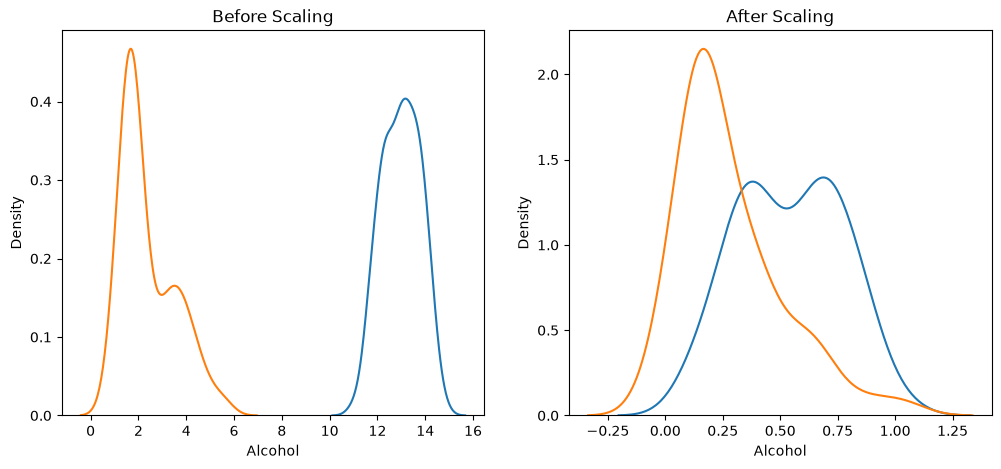

In [23]:
fig, (ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))


ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Alcohol'],ax=ax1)
sns.kdeplot(X_train['Malic_Acid'],ax=ax1)

ax2.set_title('After Scaling')
sns.kdeplot(X_train_scaled['Alcohol'],ax=ax2)
sns.kdeplot(X_train_scaled['Malic_Acid'],ax=ax2)

plt.show()

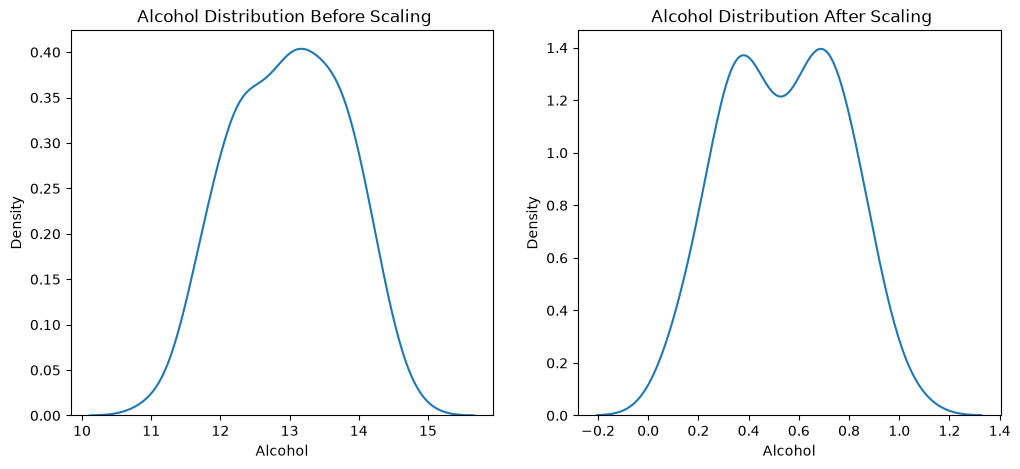

In [25]:
fig, (ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))


ax1.set_title(' Alcohol Distribution Before Scaling')
sns.kdeplot(X_train['Alcohol'],ax=ax1)

ax2.set_title(' Alcohol Distribution After Scaling')
sns.kdeplot(X_train_scaled['Alcohol'],ax=ax2)
plt.show()

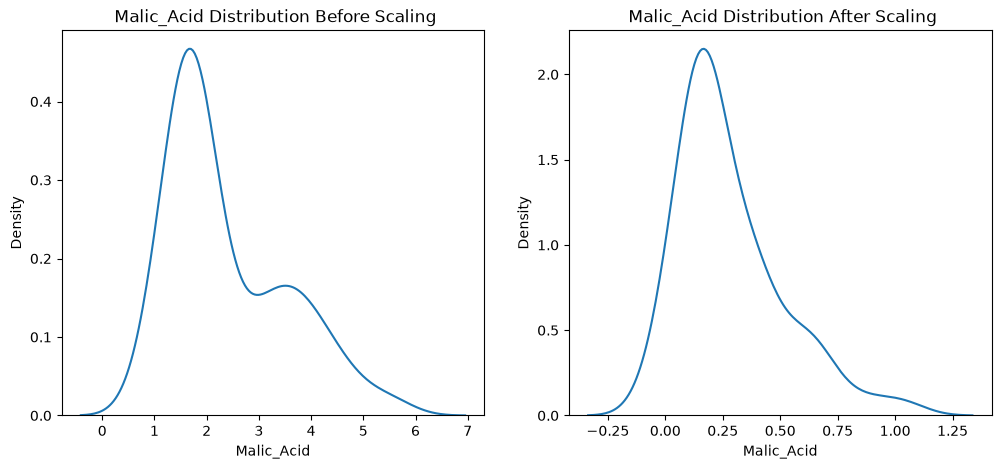

In [24]:
fig, (ax1,ax2)=plt.subplots(ncols=2,figsize=(12,5))


ax1.set_title(' Malic_Acid Distribution Before Scaling')
sns.kdeplot(X_train['Malic_Acid'],ax=ax1)

ax2.set_title(' Malic_Acid Distribution After Scaling')
sns.kdeplot(X_train_scaled['Malic_Acid'],ax=ax2)
plt.show()